# 05 — Dataset Partitioning and Split Diagnostics

## Task 2: multiclass classification — synthetic sleep-profile dataset

This notebook demonstrates common holdout strategies for **multiclass classification**. It does not train a predictive model and it does not build an end-to-end preprocessing pipeline.

The central questions are:

1. How should observations be assigned to TRAIN, VALIDATION, and TEST?
2. What does stratification preserve?
3. How can we verify that the partitions are disjoint and reproducible?
4. How can we inspect whether the target and predictor spaces remain reasonably represented?

## Learning objectives

After completing this notebook, students should be able to:

- distinguish TRAIN, VALIDATION, and TEST roles;
- explain when a train/test design is enough;
- explain when a dedicated validation set is useful;
- compare random and stratified classification splits;
- generate a reproducible stratified `70/15/15` partition;
- verify identifier disjointness and complete sample coverage;
- compare class proportions across partitions;
- inspect numerical and categorical predictor drift;
- visualize TRAIN, VALIDATION, and TEST in a PCA space fitted using TRAIN only;
- recognize that advanced group-, cluster-, distance-, and homology-aware splits answer different generalization questions.

## 1. Scope and an important ordering note

This is notebook `05` because splitting is being introduced after the earlier concepts. **That is a teaching order, not the operational order of a final machine-learning workflow.**

When preparing a real model, the partition should be defined before fitting data-dependent transformations such as scaling or supervised feature selection. The earlier notebooks created their own internal training splits whenever they needed to learn such parameters.

A later end-to-end preparation notebook will integrate these operations in the correct order.

## 2. Imports and reproducibility

In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

RANDOM_STATE = 42
sns.set_theme(style="whitegrid", context="notebook")
PASTEL = sns.color_palette("pastel")

## 3. Project paths and analytical roles

In [2]:
def find_project_root(start: Path) -> Path:
    start = start.resolve()
    for candidate in [start, *start.parents]:
        if (candidate / "data").is_dir() and (candidate / "notebooks").is_dir():
            return candidate
    raise FileNotFoundError(
        "Could not locate the repository root. Run the notebook from inside the project."
    )


def three_way_random_split(df, train_fraction=0.70, validation_fraction=0.15, test_fraction=0.15):
    if not np.isclose(train_fraction + validation_fraction + test_fraction, 1.0):
        raise ValueError("Split fractions must sum to 1.0")

    holdout_fraction = validation_fraction + test_fraction
    train_df, holdout_df = train_test_split(
        df,
        test_size=holdout_fraction,
        random_state=RANDOM_STATE,
    )
    relative_test_fraction = test_fraction / holdout_fraction
    validation_df, test_df = train_test_split(
        holdout_df,
        test_size=relative_test_fraction,
        random_state=RANDOM_STATE,
    )
    return train_df.copy(), validation_df.copy(), test_df.copy()


def standardized_mean_difference(reference, comparison, columns):
    rows = []
    for feature in columns:
        train_mean = reference[feature].mean()
        train_sd = reference[feature].std(ddof=1)
        comparison_mean = comparison[feature].mean()
        smd = np.nan if np.isclose(train_sd, 0) else (comparison_mean - train_mean) / train_sd
        rows.append({
            "feature": feature,
            "train_mean": train_mean,
            "comparison_mean": comparison_mean,
            "smd": smd,
            "abs_smd": abs(smd) if pd.notna(smd) else np.nan,
        })
    return pd.DataFrame(rows)


def verify_three_way_split(full_df, train_df, validation_df, test_df, id_column):
    train_ids = set(train_df[id_column])
    validation_ids = set(validation_df[id_column])
    test_ids = set(test_df[id_column])

    assert train_ids.isdisjoint(validation_ids)
    assert train_ids.isdisjoint(test_ids)
    assert validation_ids.isdisjoint(test_ids)
    assert train_ids | validation_ids | test_ids == set(full_df[id_column])
    assert len(train_df) + len(validation_df) + len(test_df) == len(full_df)

    return pd.DataFrame({
        "split": ["train", "validation", "test"],
        "n": [len(train_df), len(validation_df), len(test_df)],
        "fraction": [len(train_df) / len(full_df), len(validation_df) / len(full_df), len(test_df) / len(full_df)],
    })



def three_way_stratified_split(df, target_column, train_fraction=0.70, validation_fraction=0.15, test_fraction=0.15):
    if not np.isclose(train_fraction + validation_fraction + test_fraction, 1.0):
        raise ValueError("Split fractions must sum to 1.0")

    holdout_fraction = validation_fraction + test_fraction
    train_df, holdout_df = train_test_split(
        df,
        test_size=holdout_fraction,
        stratify=df[target_column],
        random_state=RANDOM_STATE,
    )
    relative_test_fraction = test_fraction / holdout_fraction
    validation_df, test_df = train_test_split(
        holdout_df,
        test_size=relative_test_fraction,
        stratify=holdout_df[target_column],
        random_state=RANDOM_STATE,
    )
    return train_df.copy(), validation_df.copy(), test_df.copy()


def class_distribution_table(parts, target_column):
    rows = []
    for split_name, split_df in parts.items():
        counts = split_df[target_column].value_counts(dropna=False)
        props = split_df[target_column].value_counts(normalize=True, dropna=False)
        for label in sorted(counts.index, key=str):
            rows.append({
                "split": split_name,
                "label": label,
                "count": int(counts[label]),
                "proportion": float(props[label]),
            })
    return pd.DataFrame(rows)



def pca_split_projection(train_df, validation_df, test_df, numerical_columns, id_column, target_column):
    scaler = StandardScaler()
    train_scaled = scaler.fit_transform(train_df[numerical_columns])
    validation_scaled = scaler.transform(validation_df[numerical_columns])
    test_scaled = scaler.transform(test_df[numerical_columns])

    pca = PCA(n_components=min(5, len(numerical_columns)), random_state=RANDOM_STATE)
    train_scores = pca.fit_transform(train_scaled)
    validation_scores = pca.transform(validation_scaled)
    test_scores = pca.transform(test_scaled)

    def make_frame(scores, source, split_name):
        frame = pd.DataFrame(scores, columns=[f"PC{i+1}" for i in range(scores.shape[1])])
        frame[id_column] = source[id_column].to_numpy()
        frame[target_column] = source[target_column].to_numpy()
        frame["split"] = split_name
        return frame

    scores = pd.concat([
        make_frame(train_scores, train_df, "train"),
        make_frame(validation_scores, validation_df, "validation"),
        make_frame(test_scores, test_df, "test"),
    ], ignore_index=True)

    explained = pd.DataFrame({
        "component": [f"PC{i+1}" for i in range(len(pca.explained_variance_ratio_))],
        "explained_variance_ratio": pca.explained_variance_ratio_,
    })

    centroid_rows = []
    train_centroid = scores.loc[scores["split"] == "train", [c for c in scores.columns if c.startswith("PC")]].mean().to_numpy()
    for split_name in ["train", "validation", "test"]:
        centroid = scores.loc[scores["split"] == split_name, [c for c in scores.columns if c.startswith("PC")]].mean().to_numpy()
        centroid_rows.append({
            "split": split_name,
            "distance_to_train_centroid": float(np.linalg.norm(centroid - train_centroid)),
        })

    return scores, explained, pd.DataFrame(centroid_rows)


PROJECT_ROOT = find_project_root(Path.cwd())
DATASET_DIR = PROJECT_ROOT / "data" / "synthetic_sleep_profiles"
FEATURE_DATA_PATH = DATASET_DIR / "feature_data" / "synthetic_sleep_profiles_engineered.csv"
PREPROCESSING_REPORT_PATH = DATASET_DIR / "processed_data" / "preprocessing_report.json"
FEATURE_MANIFEST_PATH = PROJECT_ROOT / "results" / "synthetic_sleep_profiles" / "feature_engineering_selection" / "feature_selection_manifest.json"
RESULTS_DIR = PROJECT_ROOT / "results" / "synthetic_sleep_profiles" / "dataset_splitting"
FIGURES_DIR = RESULTS_DIR / "figures"
TABLES_DIR = RESULTS_DIR / "tables"

for directory in [FIGURES_DIR, TABLES_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

if not FEATURE_DATA_PATH.exists():
    raise FileNotFoundError("Engineered feature data are missing. Run notebook 03 first.")
if not PREPROCESSING_REPORT_PATH.exists() or not FEATURE_MANIFEST_PATH.exists():
    raise FileNotFoundError("Required metadata are missing. Run preprocessing and feature-selection notebooks first.")

with open(PREPROCESSING_REPORT_PATH, encoding="utf-8") as handle:
    preprocessing_report = json.load(handle)
with open(FEATURE_MANIFEST_PATH, encoding="utf-8") as handle:
    feature_manifest = json.load(handle)

df = pd.read_csv(FEATURE_DATA_PATH)
ID_COLUMN = preprocessing_report["identifier_column"]
TARGET_COLUMN = preprocessing_report["target_column"]
NUMERICAL_COLUMNS = feature_manifest["original_numerical_features"] + feature_manifest["engineered_numerical_features"]
CATEGORICAL_COLUMNS = feature_manifest["categorical_features"]

print("Dataset shape:", df.shape)
print("Identifier:", ID_COLUMN)
print("Target:", TARGET_COLUMN)
print("Numerical predictors:", len(NUMERICAL_COLUMNS))
print("Categorical predictors:", len(CATEGORICAL_COLUMNS))
display(df.head())

Dataset shape: (1200, 28)
Identifier: participant_id
Target: sleep_profile
Numerical predictors: 20
Categorical predictors: 6


,participant_id,age,sex_female,height_cm,weight_kg,bmi,sleep_duration_hours,sleep_efficiency_pct,sleep_latency_min,night_awakenings,...,regular_exercise,evening_alcohol,loud_snoring,anxiety_history,sleep_profile,sleep_duration_deviation_8h,sleep_efficiency_deficit_pct,sleep_fragmentation_per_hour,circadian_disruption_index,behavioral_risk_count
0,SP0001,32,0,167.8,81.2,28.8,6.93,72.8,34.1,2,...,0,0,0,0,circadian_disruption,1.07,27.2,0.288600,3.223333,2
1,SP0002,49,0,177.2,72.5,23.1,6.85,88.8,27.9,1,...,1,0,0,0,circadian_disruption,1.15,11.2,0.145985,4.440000,1
2,SP0003,18,0,161.7,54.1,20.7,7.68,78.5,19.6,3,...,1,0,0,0,healthy_sleep,0.32,21.5,0.390625,2.110000,0
3,SP0004,67,0,188.9,96.8,27.1,7.79,89.5,4.2,3,...,1,1,0,0,healthy_sleep,0.21,10.5,0.385109,0.756667,1
4,SP0005,55,1,155.4,53.0,21.9,6.44,75.6,49.6,4,...,1,0,0,0,insomnia,1.56,24.4,0.621118,1.920000,0


## 4. When do we need validation data?

A simple **TRAIN/TEST** design is often enough when all development decisions are made using cross-validation inside TRAIN. This is especially attractive when the dataset is limited.

A fixed **TRAIN/VALIDATION/TEST** design is useful when a development procedure repeatedly needs a stable validation set, for example early stopping, checkpoint selection, manual threshold selection, or repeated model comparison.

In this notebook we demonstrate both. The final demonstration partition uses `70/15/15` only because it is easy to visualize. It is not a universal recommendation.

# Part I — Random versus stratified train/test splitting

## 5. Random 80/20 holdout

A random split does not explicitly preserve class frequencies. With a reasonably large balanced dataset it may still be close by chance, but stratification makes the class-composition objective explicit.

In [3]:
random_train, random_test = train_test_split(
    df,
    test_size=0.20,
    random_state=RANDOM_STATE,
)

random_distribution = class_distribution_table(
    {"full": df, "train": random_train, "test": random_test},
    TARGET_COLUMN,
)
display(random_distribution.assign(proportion_pct=lambda x: 100 * x["proportion"]).round(2))

,split,label,count,proportion,proportion_pct
0,full,circadian_disruption,328,0.27,27.33
1,full,healthy_sleep,283,0.24,23.58
2,full,insomnia,291,0.24,24.25
3,full,sleep_apnea,298,0.25,24.83
4,train,circadian_disruption,260,0.27,27.08
5,train,healthy_sleep,223,0.23,23.23
6,train,insomnia,239,0.25,24.90
7,train,sleep_apnea,238,0.25,24.79
8,test,circadian_disruption,68,0.28,28.33
9,test,healthy_sleep,60,0.25,25.00


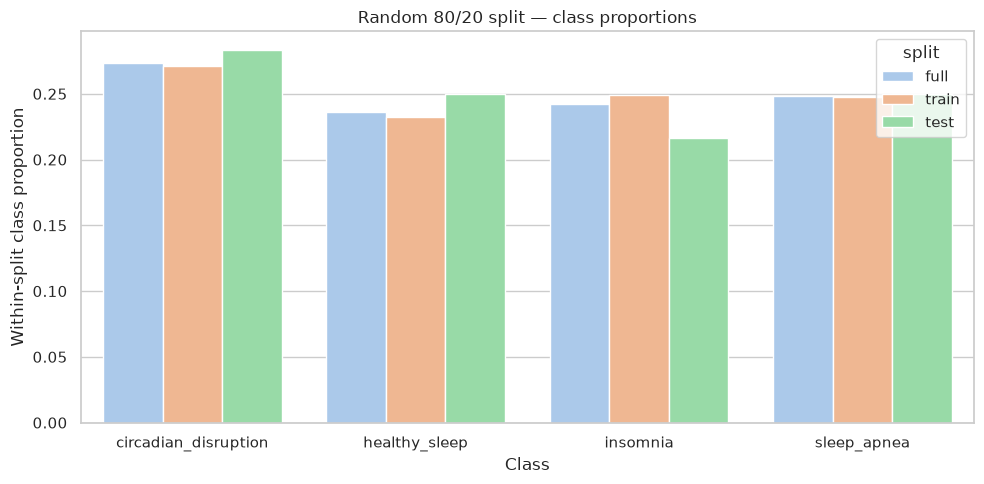

In [4]:
plt.figure(figsize=(10, 5))
sns.barplot(
    data=random_distribution,
    x="label",
    y="proportion",
    hue="split",
    palette="pastel",
)
plt.ylabel("Within-split class proportion")
plt.xlabel("Class")
plt.title("Random 80/20 split — class proportions")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "01_random_split_class_proportions.png", dpi=160, bbox_inches="tight")
plt.show()

## 6. Stratified 80/20 holdout

`stratify=target` asks the splitter to preserve the label distribution as closely as the sample counts allow. Stratification **does not balance the classes**; it preserves the existing imbalance.

In [5]:
stratified_train, stratified_test = train_test_split(
    df,
    test_size=0.20,
    stratify=df[TARGET_COLUMN],
    random_state=RANDOM_STATE,
)

stratified_distribution = class_distribution_table(
    {"full": df, "train": stratified_train, "test": stratified_test},
    TARGET_COLUMN,
)
display(stratified_distribution.assign(proportion_pct=lambda x: 100 * x["proportion"]).round(2))

,split,label,count,proportion,proportion_pct
0,full,circadian_disruption,328,0.27,27.33
1,full,healthy_sleep,283,0.24,23.58
2,full,insomnia,291,0.24,24.25
3,full,sleep_apnea,298,0.25,24.83
4,train,circadian_disruption,262,0.27,27.29
5,train,healthy_sleep,227,0.24,23.65
6,train,insomnia,233,0.24,24.27
7,train,sleep_apnea,238,0.25,24.79
8,test,circadian_disruption,66,0.28,27.50
9,test,healthy_sleep,56,0.23,23.33


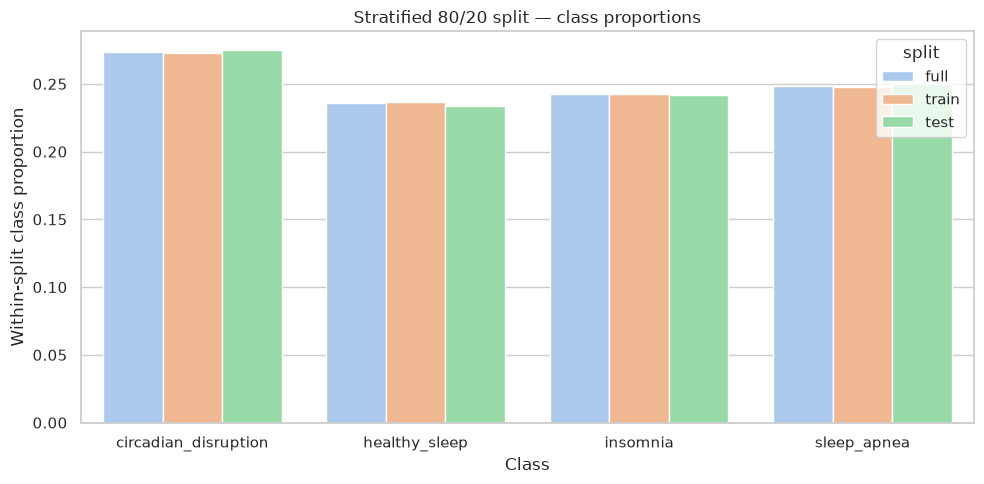

In [6]:
plt.figure(figsize=(10, 5))
sns.barplot(
    data=stratified_distribution,
    x="label",
    y="proportion",
    hue="split",
    palette="pastel",
)
plt.ylabel("Within-split class proportion")
plt.xlabel("Class")
plt.title("Stratified 80/20 split — class proportions")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "02_stratified_split_class_proportions.png", dpi=160, bbox_inches="tight")
plt.show()

### Interpretation

With this synthetic dataset, both strategies may look reasonable because the sample size is not tiny. The value of stratification is that preservation of class composition is part of the algorithm rather than an accident of the random draw.

For rare classes, this distinction can become much more important.

# Part II — A stratified TRAIN / VALIDATION / TEST demonstration

## 7. Create a reproducible 70/15/15 split

In [7]:
train_df, validation_df, test_df = three_way_stratified_split(
    df,
    TARGET_COLUMN,
    train_fraction=0.70,
    validation_fraction=0.15,
    test_fraction=0.15,
)

split_size_table = verify_three_way_split(
    df, train_df, validation_df, test_df, ID_COLUMN
)
display(split_size_table.assign(fraction_pct=lambda x: 100 * x["fraction"]).round(2))

,split,n,fraction,fraction_pct
0,train,840,0.70,70.0
1,validation,180,0.15,15.0
2,test,180,0.15,15.0


## 8. Verify class composition across all three partitions

In [8]:
parts = {"full": df, "train": train_df, "validation": validation_df, "test": test_df}
class_distribution = class_distribution_table(parts, TARGET_COLUMN)
class_distribution["proportion_pct"] = 100 * class_distribution["proportion"]
display(class_distribution.round(3))

class_distribution.to_csv(TABLES_DIR / "class_distribution.csv", index=False)
split_size_table.to_csv(TABLES_DIR / "split_sizes.csv", index=False)

,split,label,count,proportion,proportion_pct
0,full,circadian_disruption,328,0.273,27.333
1,full,healthy_sleep,283,0.236,23.583
2,full,insomnia,291,0.242,24.250
3,full,sleep_apnea,298,0.248,24.833
4,train,circadian_disruption,229,0.273,27.262
5,train,healthy_sleep,198,0.236,23.571
6,train,insomnia,204,0.243,24.286
7,train,sleep_apnea,209,0.249,24.881
8,validation,circadian_disruption,50,0.278,27.778
9,validation,healthy_sleep,43,0.239,23.889


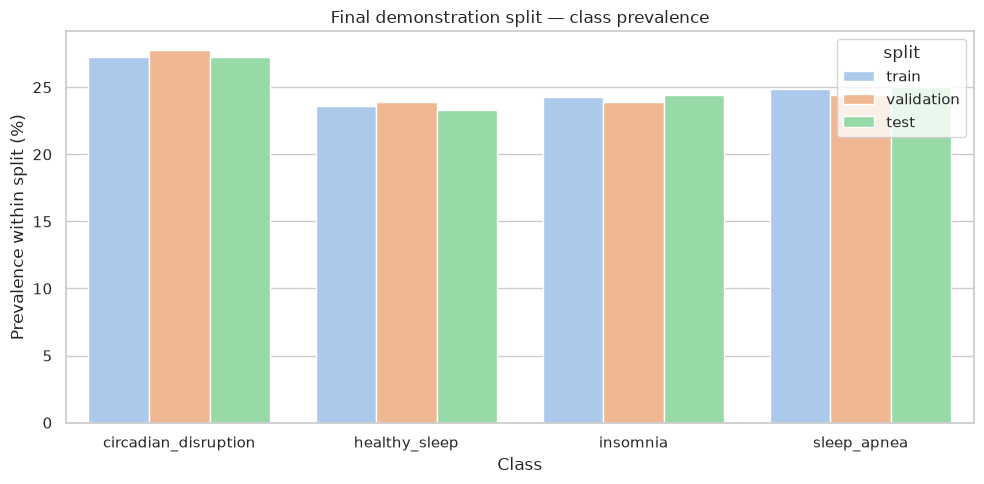

In [9]:
plot_data = class_distribution.loc[class_distribution["split"] != "full"].copy()
plt.figure(figsize=(10, 5))
sns.barplot(
    data=plot_data,
    x="label",
    y="proportion_pct",
    hue="split",
    palette="pastel",
)
plt.ylabel("Prevalence within split (%)")
plt.xlabel("Class")
plt.title("Final demonstration split — class prevalence")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "03_final_split_class_prevalence.png", dpi=160, bbox_inches="tight")
plt.show()

# Part III — Inspect predictor-space differences

Even with a well-stratified target, predictor distributions will not be identical. Random sampling naturally produces differences.

The objective is to identify accidental or scientifically problematic shifts, not to force TRAIN, VALIDATION, and TEST to be numerically identical.

## 9. Numerical predictors — standardized mean differences

For each numerical predictor we compare VALIDATION and TEST means against TRAIN in units of the TRAIN standard deviation. This is a descriptive diagnostic, not a formal pass/fail test.

In [10]:
validation_smd = standardized_mean_difference(train_df, validation_df, NUMERICAL_COLUMNS)
validation_smd["comparison_split"] = "validation"

test_smd = standardized_mean_difference(train_df, test_df, NUMERICAL_COLUMNS)
test_smd["comparison_split"] = "test"

smd_table = pd.concat([validation_smd, test_smd], ignore_index=True)
smd_table = smd_table.sort_values("abs_smd", ascending=False).reset_index(drop=True)
display(smd_table.head(20).round(3))
smd_table.to_csv(TABLES_DIR / "numerical_standardized_mean_differences.csv", index=False)

,feature,train_mean,comparison_mean,smd,abs_smd,comparison_split
0,daily_steps,8397.019,8003.056,-0.170,0.170,test
1,stress_score_0_10,4.825,5.129,0.152,0.152,validation
2,night_awakenings,1.711,1.539,-0.123,0.123,test
3,sleep_fragmentation_per_hour,0.251,0.226,-0.120,0.120,test
4,height_cm,170.088,171.204,0.119,0.119,validation
5,age,44.823,46.572,0.115,0.115,test
6,height_cm,170.088,171.083,0.106,0.106,test
7,age,44.823,46.106,0.084,0.084,validation
8,behavioral_risk_count,0.949,0.889,-0.073,0.073,test
9,night_awakenings,1.711,1.622,-0.063,0.063,validation


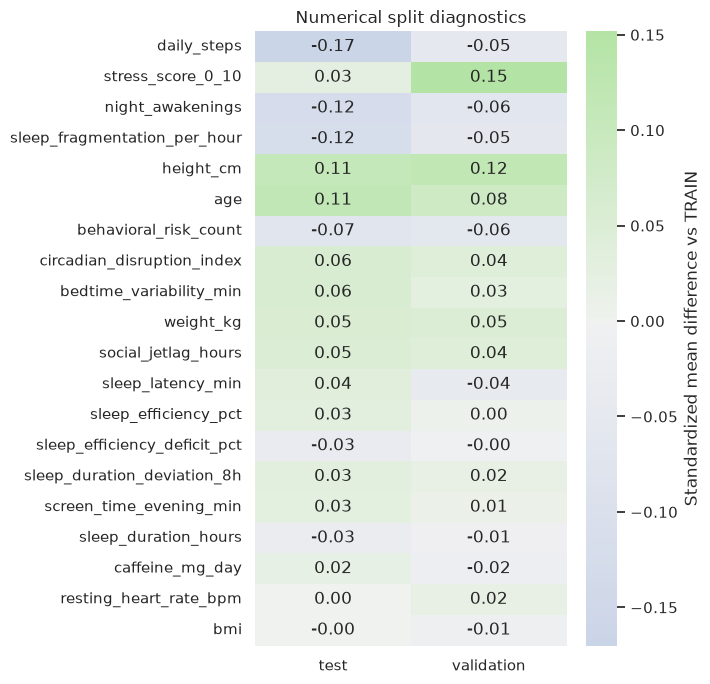

In [11]:
smd_heatmap = smd_table.pivot(index="feature", columns="comparison_split", values="smd")
smd_heatmap = smd_heatmap.loc[smd_heatmap.abs().max(axis=1).sort_values(ascending=False).index]

plt.figure(figsize=(7, max(7, 0.30 * len(smd_heatmap))))
sns.heatmap(
    smd_heatmap,
    cmap=sns.diverging_palette(250, 120, s=45, l=85, as_cmap=True),
    center=0,
    annot=True,
    fmt=".2f",
    cbar_kws={"label": "Standardized mean difference vs TRAIN"},
)
plt.title("Numerical split diagnostics")
plt.xlabel("")
plt.ylabel("")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "04_numerical_smd_heatmap.png", dpi=160, bbox_inches="tight")
plt.show()

## 10. Categorical predictors — prevalence differences

The current synthetic datasets use binary categorical indicators. For each feature, we compare the percentage of `1` values in VALIDATION and TEST against TRAIN.

In [12]:
categorical_rows = []
for feature in CATEGORICAL_COLUMNS:
    train_prevalence = 100 * train_df[feature].mean()
    for split_name, split_df in [("validation", validation_df), ("test", test_df)]:
        prevalence = 100 * split_df[feature].mean()
        categorical_rows.append({
            "feature": feature,
            "split": split_name,
            "train_prevalence_pct": train_prevalence,
            "split_prevalence_pct": prevalence,
            "difference_percentage_points": prevalence - train_prevalence,
        })

categorical_drift = pd.DataFrame(categorical_rows).sort_values(
    "difference_percentage_points", key=lambda s: s.abs(), ascending=False
)
display(categorical_drift.head(20).round(2))
categorical_drift.to_csv(TABLES_DIR / "categorical_prevalence_differences.csv", index=False)

,feature,split,train_prevalence_pct,split_prevalence_pct,difference_percentage_points
7,evening_alcohol,test,23.10,16.11,-6.98
4,regular_exercise,validation,60.71,67.22,6.51
6,evening_alcohol,validation,23.10,18.89,-4.21
11,anxiety_history,test,20.60,17.22,-3.37
10,anxiety_history,validation,20.60,23.89,3.29
5,regular_exercise,test,60.71,57.78,-2.94
2,shift_worker,validation,11.90,14.44,2.54
0,sex_female,validation,52.50,50.00,-2.50
8,loud_snoring,validation,5.71,3.33,-2.38
1,sex_female,test,52.50,54.44,1.94


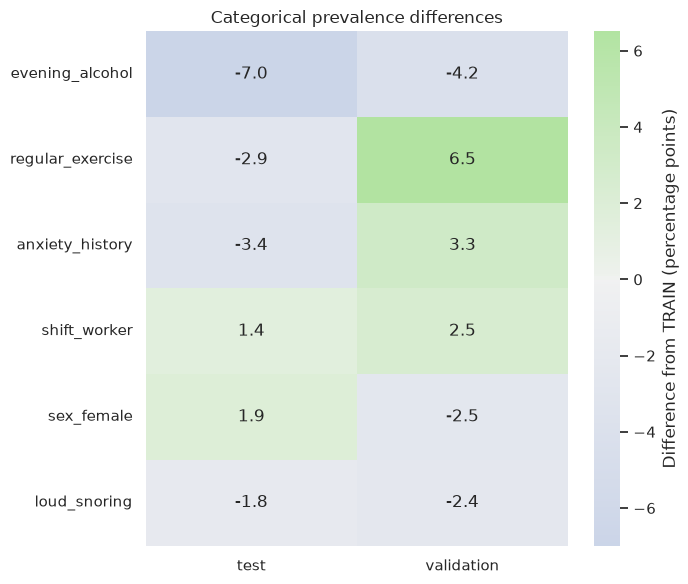

In [13]:
categorical_heatmap = categorical_drift.pivot(
    index="feature", columns="split", values="difference_percentage_points"
)
categorical_heatmap = categorical_heatmap.loc[
    categorical_heatmap.abs().max(axis=1).sort_values(ascending=False).index
]

plt.figure(figsize=(7, max(6, 0.32 * len(categorical_heatmap))))
sns.heatmap(
    categorical_heatmap,
    cmap=sns.diverging_palette(250, 120, s=45, l=85, as_cmap=True),
    center=0,
    annot=True,
    fmt=".1f",
    cbar_kws={"label": "Difference from TRAIN (percentage points)"},
)
plt.title("Categorical prevalence differences")
plt.xlabel("")
plt.ylabel("")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "05_categorical_prevalence_differences.png", dpi=160, bbox_inches="tight")
plt.show()

# Part IV — Multivariate split-space diagnostics

## 11. PCA fitted on TRAIN only

PCA is used here only to visualize the numerical predictor space. We fit both the scaler and PCA using TRAIN, then transform VALIDATION and TEST with those learned parameters.

This follows the same leakage-safe principle that would apply if PCA were part of a predictive workflow.

In [14]:
pca_scores, pca_explained, pca_centroid_shift = pca_split_projection(
    train_df, validation_df, test_df, NUMERICAL_COLUMNS, ID_COLUMN, TARGET_COLUMN
)

display(pca_explained.round(4))
display(pca_centroid_shift.round(4))

pca_scores.to_csv(TABLES_DIR / "pca_split_scores.csv", index=False)
pca_explained.to_csv(TABLES_DIR / "pca_explained_variance.csv", index=False)
pca_centroid_shift.to_csv(TABLES_DIR / "pca_centroid_shift.csv", index=False)

,component,explained_variance_ratio
0,PC1,0.1816
1,PC2,0.1352
2,PC3,0.0999
3,PC4,0.0921
4,PC5,0.0808


,split,distance_to_train_centroid
0,train,0.0000
1,validation,0.1113
2,test,0.1795


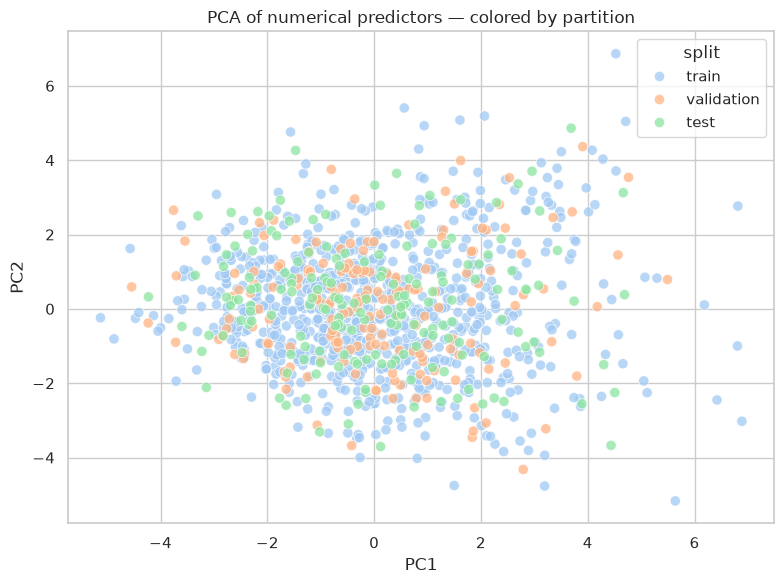

In [15]:
plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=pca_scores,
    x="PC1",
    y="PC2",
    hue="split",
    palette="pastel",
    alpha=0.75,
    s=55,
)
plt.title("PCA of numerical predictors — colored by partition")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "06_pca_by_split.png", dpi=160, bbox_inches="tight")
plt.show()

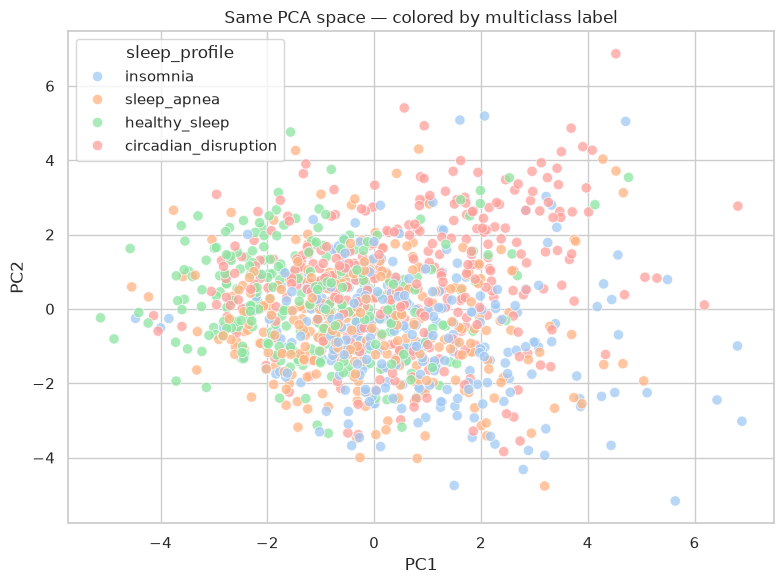

In [16]:
plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=pca_scores,
    x="PC1",
    y="PC2",
    hue=TARGET_COLUMN,
    palette="pastel",
    alpha=0.75,
    s=55,
)
plt.title("Same PCA space — colored by multiclass label")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "07_pca_by_label.png", dpi=160, bbox_inches="tight")
plt.show()

### How to read these PCA figures

A useful split normally shows TRAIN, VALIDATION, and TEST occupying broadly overlapping regions when all three are intended to represent the same population. Exact overlap is neither expected nor required.

If TEST occupies a clearly separate region, ask why. It could indicate:

- an accidental random-sampling effect;
- a data-quality issue;
- a real distribution shift;
- a deliberately harder evaluation scenario.

PCA is only one projection and should not be treated as a definitive distribution-equality test.

# Part V — Save the realized split

## 12. Export sample-level assignments

Saving assignments makes the demonstration reproducible even if software versions or random-number implementations change later.

In [17]:
split_assignments = pd.concat([
    train_df[[ID_COLUMN, TARGET_COLUMN]].assign(split="train"),
    validation_df[[ID_COLUMN, TARGET_COLUMN]].assign(split="validation"),
    test_df[[ID_COLUMN, TARGET_COLUMN]].assign(split="test"),
], ignore_index=True)

split_assignments = split_assignments.sort_values(ID_COLUMN).reset_index(drop=True)
split_assignments.to_csv(TABLES_DIR / "split_assignments_70_15_15.csv", index=False)

split_manifest = {
    "strategy": "stratified train/validation/test holdout",
    "random_state": RANDOM_STATE,
    "train_fraction": 0.70,
    "validation_fraction": 0.15,
    "test_fraction": 0.15,
    "identifier_column": ID_COLUMN,
    "target_column": TARGET_COLUMN,
    "n_total": int(len(df)),
    "n_train": int(len(train_df)),
    "n_validation": int(len(validation_df)),
    "n_test": int(len(test_df)),
    "note": "Demonstration split only; the later end-to-end ML preparation notebook will define the operational modelling workflow.",
}
with open(RESULTS_DIR / "split_manifest.json", "w", encoding="utf-8") as handle:
    json.dump(split_manifest, handle, indent=2)

print("Exported:", (TABLES_DIR / "split_assignments_70_15_15.csv").relative_to(PROJECT_ROOT))
print("Exported:", (RESULTS_DIR / "split_manifest.json").relative_to(PROJECT_ROOT))

Exported: results/synthetic_sleep_profiles/dataset_splitting/tables/split_assignments_70_15_15.csv
Exported: results/synthetic_sleep_profiles/dataset_splitting/split_manifest.json


# 13. What this notebook did — and did not do

We demonstrated:

```text
random train/test
stratified train/test
stratified train/validation/test
class-composition diagnostics
numerical drift diagnostics
categorical prevalence diagnostics
PCA visualization of split space
reproducible split export
```

We deliberately did **not**:

- train a predictive model;
- optimize hyperparameters;
- fit a complete preprocessing pipeline;
- perform resampling or class balancing;
- implement group-aware, distance-aware, cluster-aware, or homology-aware splitting.

Those methods are important, but the purpose here is to understand ordinary classification partitioning first.

## Final takeaway

For ordinary independent classification data, stratification is a useful default because it makes class preservation explicit. But class balance is only one property of a split. Always verify identifiers, target composition, predictor space, and any domain-specific dependency constraints.

The correct split is the one that represents the kind of unseen data the model is expected to face.